<a href="https://colab.research.google.com/github/Ridima28/Brain-Tumor-Detection-system/blob/main/Brain_Tumor_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing the libraries

In [3]:
import os # For directory and file operations
import numpy as np # For numerical operations and handling image arrays
import random # For generating random values for augmentation
import json
from zipfile import ZipFile
from PIL import Image, ImageEnhance # For image processing and enhancement
from tensorflow.keras.preprocessing. image import load_img # For loading images
from tensorflow.keras.models import Sequential # For building the model
from tensorflow.keras. layers import Input, Flatten, Dropout, Dense # For model layers
from tensorflow.keras.optimizers import Adam # For optimizer
from tensorflow.keras.applications import VGG16 # For using VGG16 model
from sklearn.utils import shuffle # For shuffling the data

In [4]:
kaggle_creds = json.load(open('/content/kaggle.json'))
os.environ['KAGGLE_USERNAME'] = kaggle_creds['username']
os.environ['KAGGLE_KEY'] = kaggle_creds['key']

In [5]:
!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:01<00:00, 96.0MB/s]



In [6]:
with ZipFile("brain-tumor-mri-dataset.zip", 'r') as zip_ref:
  zip_ref.extractall()

**LOADING THE DATASET**

In [7]:
# Directories for training and testing data
train_dir = '/content/Training/'
test_dir = '/content/Testing'

# Load and shuffle the train data
train_paths = []
train_labels = []
for label in os.listdir(train_dir):
    for image in os.listdir(os.path.join(train_dir, label)):
        train_paths.append(os.path.join(train_dir, label, image))
        train_labels.append(label)

train_paths, train_labels = shuffle(train_paths, train_labels)

# Load and shuffle the test data
test_paths = []
test_labels = []
for label in os.listdir(test_dir):
    for image in os.listdir(os.path.join(test_dir, label)):
        test_paths.append(os.path.join(test_dir, label, image))
        test_labels.append(label)

test_paths, test_labels = shuffle(test_paths, test_labels)

**DATA VISUALIZATION**

In [8]:
import random
import matplotlib.pyplot as plt
import seaborn

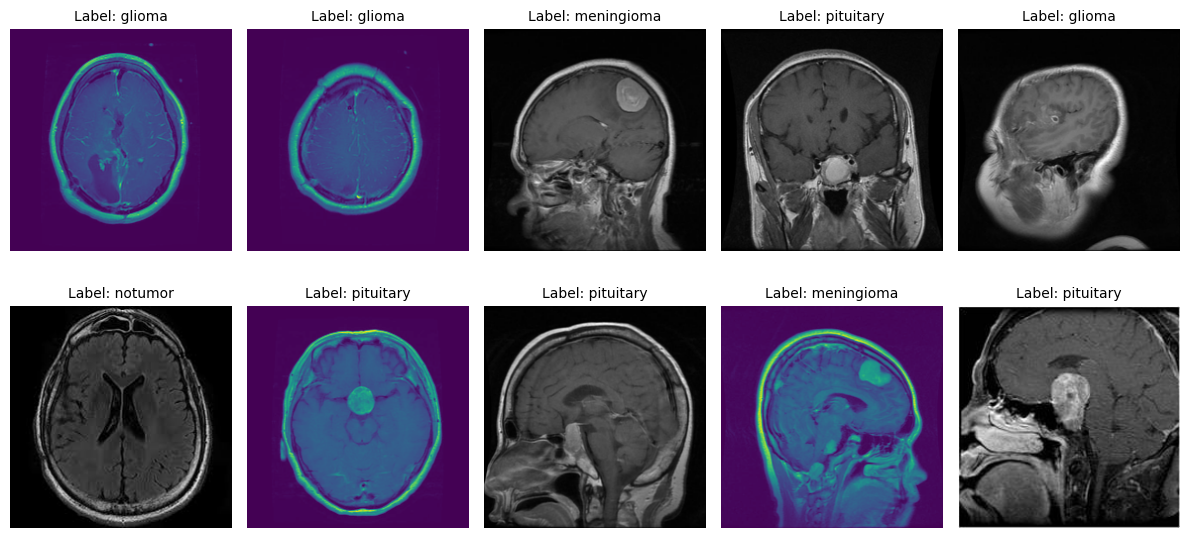

In [9]:
random_idx = random.sample(range(len(train_paths)),10)
random_idx

fig,axes = plt.subplots(2,5, figsize = (12,6))
axes = axes.flatten()

for i, inx in enumerate(random_idx):
    # Load image
    img_path = train_paths[inx]
    img = Image.open(img_path)
    img = img.resize((224, 224))

    # Display image
    axes[i].imshow(img)
    axes[i].axis('off')  # Hide axis
    # Display class label in the second row
    axes[i].set_title(f"Label: {train_labels[inx]}", fontsize=10)

plt.tight_layout()
plt.savefig("Labeles.png")
plt.show()

**DATA PREPROCESSING**

In [40]:
# Image Augmentation function
def augment_image(image):
    image = Image.fromarray(np.uint8(image))
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))  # Random brightness
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))  # Random contrast
    image = np.array(image) / 255.0  # Normalize pixel values to [0, 1]
    return image

# Load images and apply augmentation
def open_images(paths):
    images = []
    for path in paths:
        image = load_img(path, target_size=(128,128))
        image = augment_image(image)
        images.append(image)
    return np.array(images)

# Encoding labels (convert label names to integers)
def encode_label(labels):
    unique_labels = os.listdir(train_dir)  # Ensure unique labels are determined
    encoded = [unique_labels.index(label) for label in labels]
    return np.array(encoded)

# Data generator for batching
def datagen(paths, labels, batch_size=12, epochs=1):
    for _ in range(epochs):
        for i in range(0, len(paths), batch_size):
            batch_paths = paths[i:i + batch_size]
            batch_images = open_images(batch_paths)  # Open and augment images
            batch_labels = labels[i:i + batch_size]
            batch_labels = encode_label(batch_labels)  # Encode labels
            yield batch_images, batch_labels  # Yield the batch

**MODEL TRAINING**

We will be using VGG16 model to train our model.

In [41]:
#defining the base model

base_model = VGG16(input_shape = (128,128,3), include_top=False, weights= 'imagenet')

for layer in base_model.layers:
  layer.trainable= False

base_model.layers[-2].trainable = True
base_model.layers[-3].trainable = True
base_model.layers[-4].trainable = True

model = Sequential()
model.add(Input(shape=(128,128,3)))

model.add(base_model)
model.add(Flatten())
model.add(Dropout(0.3))
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(len(os.listdir(train_dir)), activation='softmax'))

In [48]:
model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['sparse_categorical_accuracy'])

In [49]:
#Defining the parameters
batch_size = 20
steps = int(len(train_paths) / batch_size)
epochs = 10

In [ ]:
history = model.fit(datagen(train_paths, train_labels, batch_size = batch_size, epochs = epochs), epochs= epochs, steps_per_epoch = steps)

Epoch 1/10
180/280 ━━━━━━━━━━━━━━━━━━━━ 8:20 5s/step - loss: 1.4960 - sparse_categorical_accuracy: 0.2861